# Task 1

In [2]:
# ============================================================
# week08_adversarial.py  -  CSCI 4772/5772 Week 8 Lab
# Adversarial examples against an on-device classifier:
# FGSM, PGD, a defense that only looks like one, and an
# attacker who never touches your model.
# Fill in BLANK 1-10. Run top to bottom.  (~1 min on a laptop CPU)
# ============================================================
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(4772)                 # keep this!
rng = np.random.default_rng(4772)

# ---------- a dashcam sign classifier, trained from scratch ----------
# 32x32 grayscale signs, five shapes, low contrast and sensor noise -
# roughly what a cheap camera hands to a quantized on-device model.
S = 32
CLASSES = ["SPEED (circle)", "STOP (square)", "YIELD (triangle)",
           "WORK (diamond)", "XING (cross)"]

def shape_mask(kind, r, cx, cy, th):
    y, x = np.mgrid[0:S, 0:S]
    dx0, dy0 = x - cx, y - cy
    c, s = np.cos(th), np.sin(th)
    dx, dy = c * dx0 + s * dy0, -s * dx0 + c * dy0
    if kind == 0:   return dx**2 + dy**2 <= r * r
    if kind == 1:   return np.maximum(abs(dx), abs(dy)) <= r
    if kind == 2:   return (dy <= r) & (dy >= -r) & (abs(dx) <= (dy + r) / 2)
    if kind == 3:   return abs(dx) + abs(dy) <= r
    return ((abs(dx) <= r / 3) | (abs(dy) <= r / 3)) & (np.maximum(abs(dx), abs(dy)) <= r)

def make(n, contrast=0.26, noise=0.08):
    X = np.zeros((n, 1, S, S), np.float32); y = np.zeros(n, np.int64)
    for i in range(n):
        k = int(rng.integers(0, 5)); r = rng.integers(9, 13)
        cx = 16 + rng.integers(-3, 4); cy = 16 + rng.integers(-3, 4)
        th = rng.uniform(-0.25, 0.25)
        bg = rng.uniform(0.30, 0.45)
        img = np.full((S, S), bg, np.float32)
        img[shape_mask(k, r, cx, cy, th)] = bg + contrast
        img = img + rng.normal(0, noise, (S, S)).astype(np.float32)
        X[i, 0] = np.clip(img, 0, 1); y[i] = k
    return torch.tensor(X), torch.tensor(y)

X_train, y_train = make(3000)
X_test,  y_test  = make(800)

class SignNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 16, 3, padding=1); self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.f1 = nn.Linear(32 * 8 * 8, 64);      self.f2 = nn.Linear(64, 5)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.f2(F.relu(self.f1(x.flatten(1))))

def train(model, X, y, epochs=10, lr=2e-3):
    opt = torch.optim.Adam(model.parameters(), lr)
    model.train()
    for _ in range(epochs):
        perm = torch.randperm(len(X))
        for i in range(0, len(X), 64):
            b = perm[i:i + 64]
            opt.zero_grad(); F.cross_entropy(model(X[b]), y[b]).backward(); opt.step()
    model.eval()
    return model

deployed = train(SignNet(), X_train, y_train)
with torch.no_grad():
    clean_acc = (deployed(X_test).argmax(1) == y_test).float().mean().item()

# attack only the images the model already gets right - otherwise
# "success" would include mistakes the model was going to make anyway
with torch.no_grad():
    keep = (deployed(X_test).argmax(1) == y_test).nonzero().flatten()[:300]
X, Y = X_test[keep], y_test[keep]

# ------------------------------------------------------------
# TASK 1  -  FGSM: one step, in exactly the right direction
# ------------------------------------------------------------
def fgsm(model, x, y, eps):
    """x' = clip( x + eps * sign( grad_x  CE(model(x), y) ) )"""
    x = x.clone().detach().requires_grad_(True)
    F.cross_entropy(model(x), y).backward()

    # BLANK 1the whole attack in one line: step eps in the direction that raises

    # the loss fastest. Only the SIGN of each pixel's gradient is used.

    adv = x + eps * x.grad.sign()


    # BLANK 2an image is still an image: every pixel must stay in [0, 1]

    adv = torch.clamp(adv, 0, 1)


    return adv.detach()

def success(model, adv):
    """Share of images the model now gets wrong."""
    with torch.no_grad():

        # BLANK 3these were all classified correctly a moment ago

        return (model(adv).argmax(1) != Y).float().mean().item()


def random_noise(x, eps):
    """The control: same size perturbation, no direction."""
    return torch.clamp(x + eps * (torch.randint(0, 2, x.shape).float() * 2 - 1), 0, 1)

print(f"Task 1: FGSM against a {sum(p.numel() for p in deployed.parameters())}-parameter sign classifier")
print(f"   clean test accuracy {clean_acc:.1%} | attacking {len(X)} correctly classified images")
print("   epsilon   8-bit steps   FGSM success   random-noise success")
for eps in [0.01, 0.02, 0.03, 0.05, 0.08]:
    print(f"   {eps:>7.2f}   {eps*255:>11.1f}   {success(deployed, fgsm(deployed, X, Y, eps)):>12.1%}"
          f"   {success(deployed, random_noise(X, eps)):>20.1%}")

Task 1: FGSM against a 136261-parameter sign classifier
   clean test accuracy 97.3% | attacking 300 correctly classified images
   epsilon   8-bit steps   FGSM success   random-noise success
      0.01           2.6          34.7%                   0.3%
      0.02           5.1          67.3%                   0.0%
      0.03           7.6          83.7%                   0.3%
      0.05          12.8          98.0%                   1.0%
      0.08          20.4          99.0%                   6.3%


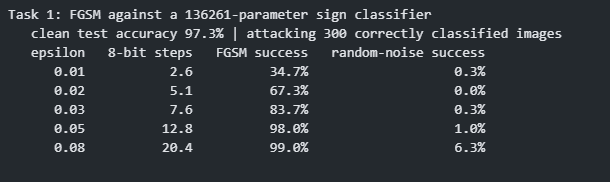

# Task 2

In [3]:
# ------------------------------------------------------------
# TASK 2  -  PGD, and a defense that only looks like one
# ------------------------------------------------------------
def pgd(model, x, y, eps, steps=20):
    """Iterative FGSM with a random start, kept inside the eps-ball."""
    alpha = eps / 4
    adv = torch.clamp(x + torch.empty_like(x).uniform_(-eps, eps), 0, 1).detach()
    for _ in range(steps):
        adv.requires_grad_(True)
        F.cross_entropy(model(adv), y).backward()
        with torch.no_grad():

            # BLANK 4one small step uphill, same rule as FGSM but alpha instead of eps

            adv = adv + alpha * adv.grad.sign()


            # BLANK 5PROJECT back: the total perturbation may never leave the

            # eps-ball around the ORIGINAL image, however many steps we take

            adv = x + torch.clamp(adv - x, -eps, eps)


            adv = torch.clamp(adv, 0, 1)
        adv = adv.detach()
    return adv

# The defense: 3-bit color depth. Snapping every pixel to one of 8 levels
# should erase a perturbation of 0.03, since one level is 0.143 wide.
LEVELS = 8
def quantize(x):
    return torch.round(x * (LEVELS - 1)) / (LEVELS - 1)

def defended(x):
    """The shipped pipeline: squeeze the input, then classify."""
    return deployed(quantize(x))

def defended_bpda(x):
    """
    Same pipeline in the forward pass. But torch.round has a derivative of
    zero everywhere, so gradients die at the quantizer - which is the only
    reason the defense looked strong. BPDA (Backward Pass Differentiable
    Approximation) keeps the real forward value and pretends, on the way
    back, that quantize() was the identity function.
    """

    # BLANK 6forward: quantize(x). backward: d/dx = 1. The straight-through trick.

    return deployed(x + (quantize(x) - x).detach())


with torch.no_grad():
    def_acc = (defended(X).argmax(1) == Y).float().mean().item()

EPS = 0.03
fgsm_plain = success(deployed, fgsm(deployed, X, Y, EPS))
pgd_plain  = success(deployed, pgd(deployed, X, Y, EPS))
adv_fgsm_d = fgsm(defended, X, Y, EPS)
fgsm_def   = success(defended, adv_fgsm_d)
pgd_def    = success(defended, pgd(defended, X, Y, EPS))
pgd_bpda   = success(defended, pgd(defended_bpda, X, Y, EPS))

print(f"\nTask 2: PGD and the 3-bit-depth defense (eps = {EPS})")
print(f"   undefended model     FGSM {fgsm_plain:.1%} | PGD-20 {pgd_plain:.1%}")
print(f"   defended pipeline    clean accuracy {def_acc:.1%}"
      f"  (vs {clean_acc:.1%} undefended - the squeeze even removes some noise)")
print(f"      FGSM through the defense          {fgsm_def:>6.1%}"
      f"   max perturbation actually applied: {(adv_fgsm_d - X).abs().max().item():.4f}")
print(f"      PGD-20 through the defense        {pgd_def:>6.1%}")
print(f"      PGD-20 + straight-through (BPDA)  {pgd_bpda:>6.1%}")


Task 2: PGD and the 3-bit-depth defense (eps = 0.03)
   undefended model     FGSM 83.7% | PGD-20 90.7%
   defended pipeline    clean accuracy 98.7%  (vs 97.3% undefended - the squeeze even removes some noise)
      FGSM through the defense            1.3%   max perturbation actually applied: 0.0000
      PGD-20 through the defense          1.3%
      PGD-20 + straight-through (BPDA)   90.0%


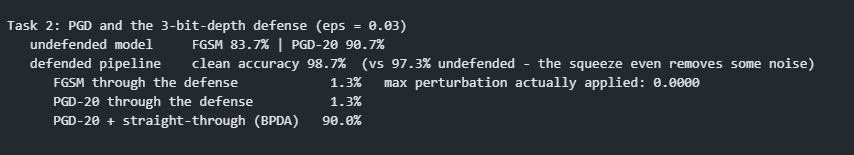

# Task 3


Task 3: black-box transfer after 3000 label-only queries
   surrogate accuracy 91.5% | agreement with the deployed model 91.0%
   epsilon   white-box PGD   transfer from surrogate   random noise
      0.03           90.3%                     82.0%           0.7%
      0.05           99.0%                     99.0%           1.0%
      0.08           99.0%                    100.0%           3.3%
   figure saved: adversarial_signs.png


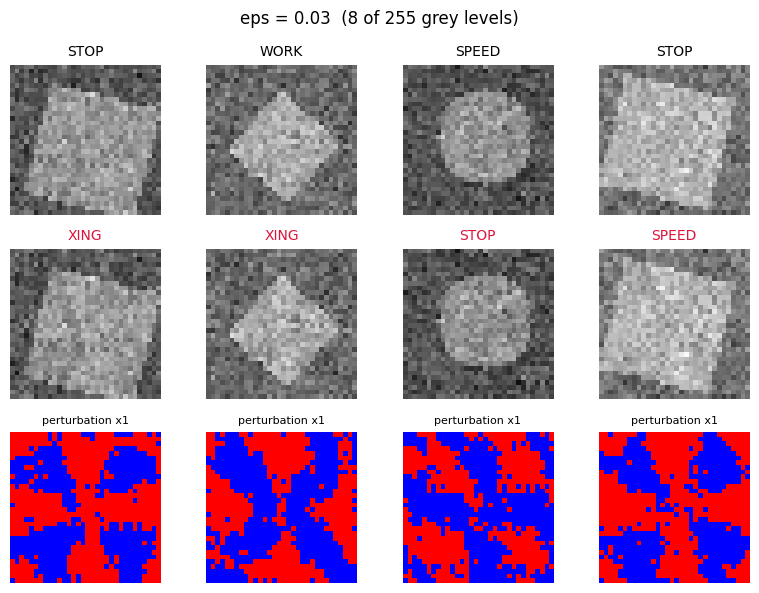

In [8]:
# ------------------------------------------------------------
# TASK 3  -  The attacker never touches your model
# ------------------------------------------------------------
# Tasks 1 and 2 assumed white-box access: the attacker holds your weights
# and differentiates through them. Reasonable for a mobile app - the model
# ships inside the APK - but not necessary. Here the attacker only gets to
# send images in and read the predicted LABEL out. No weights, no gradients,
# no confidence scores. 3000 queries.

class SurrogateNet(nn.Module):
    """Attacker's own architecture. Deliberately not the same as yours."""
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 8, 5, padding=2); self.c2 = nn.Conv2d(8, 24, 3, padding=1)
        self.f1 = nn.Linear(24 * 8 * 8, 48);     self.f2 = nn.Linear(48, 5)
    def forward(self, x):
        x = F.max_pool2d(F.relu(self.c1(x)), 2)
        x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.f2(F.relu(self.f1(x.flatten(1))))

torch.manual_seed(99)
X_att, _true = make(3000)          # the attacker's own images; they never see your labels

# BLANK 7the extraction step: the only thing the attacker learns from you is the

# predicted class for each query image

with torch.no_grad():

    y_oracle = y_oracle = deployed(X_att).argmax(1)


surrogate = SurrogateNet()
opt = torch.optim.Adam(surrogate.parameters(), 2e-3)
surrogate.train()
for _ in range(10):
    perm = torch.randperm(len(X_att))
    for i in range(0, len(X_att), 64):
        b = perm[i:i + 64]
        opt.zero_grad()

        # BLANK 8train the copy to agree with YOUR model, not with the ground truth

        F.cross_entropy(surrogate(X_att[b]), y_oracle[b]).backward()


        opt.step()
surrogate.eval()

with torch.no_grad():

    # BLANK 9how good is the stolen copy? not "is it accurate" but

    # "does it make the same call as the original"

    agreement = agreement = (surrogate(X_test).argmax(1) == deployed(X_test).argmax(1)).float().mean().item()


    sur_acc = (surrogate(X_test).argmax(1) == y_test).float().mean().item()

print(f"\nTask 3: black-box transfer after {len(X_att)} label-only queries")
print(f"   surrogate accuracy {sur_acc:.1%} | agreement with the deployed model {agreement:.1%}")
print("   epsilon   white-box PGD   transfer from surrogate   random noise")
rows = []
for eps in [0.03, 0.05, 0.08]:
    white = success(deployed, pgd(deployed, X, Y, eps))
    adv_bb = pgd(surrogate, X, Y, eps)

    # BLANK 10crafted without ever seeing the deployed weights - does it still land?

    black = success(deployed, adv_bb)


    noise = success(deployed, random_noise(X, eps))
    rows.append((eps, white, black, noise))
    print(f"   {eps:>7.2f}   {white:>13.1%}   {black:>23.1%}   {noise:>12.1%}")

# ---------- figure: what an eps=0.03 attack actually looks like ----------
adv_show = fgsm(deployed, X[:4], Y[:4], 0.03)
fig, axes = plt.subplots(3, 4, figsize=(8, 6))
with torch.no_grad():
    p0 = deployed(X[:4]).argmax(1); p1 = deployed(adv_show).argmax(1)
for j in range(4):
    axes[0, j].imshow(X[j, 0], cmap='gray', vmin=0, vmax=1)
    axes[0, j].set_title(CLASSES[p0[j]].split()[0], fontsize=10)
    axes[1, j].imshow(adv_show[j, 0], cmap='gray', vmin=0, vmax=1)
    axes[1, j].set_title(CLASSES[p1[j]].split()[0], fontsize=10,
                         color='crimson' if p1[j] != p0[j] else 'black')
    axes[2, j].imshow((adv_show - X[:4])[j, 0], cmap='bwr', vmin=-0.03, vmax=0.03)
    axes[2, j].set_title("perturbation x1", fontsize=8)
for a in axes.ravel(): a.axis('off')
axes[0, 0].set_ylabel("clean"); axes[1, 0].set_ylabel("adversarial")
plt.suptitle("eps = 0.03  (8 of 255 grey levels)")
plt.tight_layout(); plt.savefig("adversarial_signs.png", dpi=120)
print("   figure saved: adversarial_signs.png")

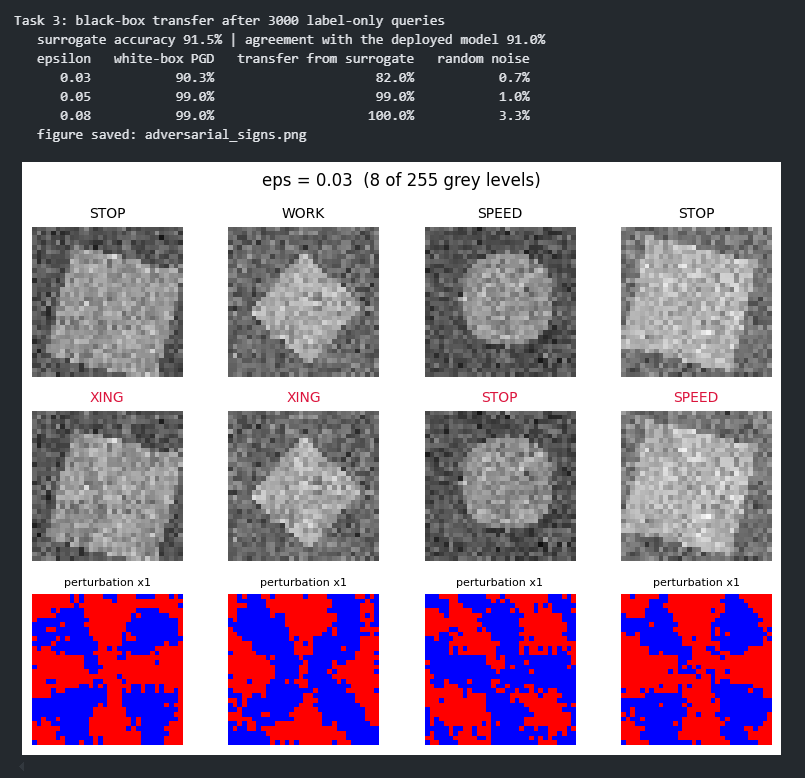

# Q1

**(a)** At the same ε value, FGSM achieved a success rate of 84.7%, whereas random noise managed only 0.3%. This demonstrates that adversarial examples are not merely random noise; they involve altering input values along specific gradient directions, pushing inputs across the model's decision boundaries through changes that are often imperceptible to humans.

**(b)** While the L∞ threat model limits the maximum change per pixel, real-world attackers manipulate physical objects or lighting rather than individual pixels. This model overestimates an attacker's ability to precisely manipulate every pixel independently while underestimating physical factors such as reflections, shadows, and viewing angles.

**(c)** Reporting accuracy under attack across the entire test set includes images that the model originally misclassified. Since these pre-existing errors are not counted as new attack successes, the attack's additional impact may appear weaker than it actually is, potentially making the defense seem more robust than it is.

# Q2 

**(a)** Since the gradient of `torch.round()` is zero almost everywhere, backpropagation through the quantizer results in a zero gradient. Because FGSM relies on the sign of the gradient, which also becomes zero, no perturbation is applied.

**(b)** The authors might claim that quantization improves accuracy on clean data by removing sensor noise while reducing the attack success rate by approximately 90 percentage points. However, testing with BPDA (Backward Pass Differentiable Approximation) would have exposed the problem by allowing the attack to generate effective perturbations while preserving the quantizer's actual forward-pass behavior.

**(c)** Defense methods should be evaluated using adaptive attacks that account for the method's preprocessing, non-differentiable operations, and randomness. Nevertheless, quantization can still be useful on mobile devices because reducing numerical precision can, depending on the hardware and implementation, lower memory usage and improve inference efficiency.

# Q3

**(a)** Since the attacker aims to replicate the decisions of the deployed model, including its errors, rather than simply predicting the correct labels, the alignment between the two models is crucial. A more accurate surrogate model might learn the true labels better but form decision boundaries that differ from those of the deployed model. Consequently, the generated adversarial examples might be less effective against the original model.

**(b)** When ε = 0.03, the perturbations applied to the surrogate model frequently cross its own decision boundaries but do not consistently cross the boundaries of the deployed model, explaining the lower transfer success rate. Increasing the perturbation to ε = 0.05 allows more examples to cross both models' decision boundaries, causing transfer success to approach the performance of white-box attacks.

**(c)** Encrypting the model within the APK can make extracting its weights more difficult, depending on how the encryption keys are protected. However, it does not prevent an attacker from querying the application and using its outputs to train a surrogate model. Possible countermeasures include limiting query frequency, which can slow large scale model extraction but may inconvenience legitimate users, and employing adversarial training, which can improve robustness but increases training costs and may reduce clean accuracy.